In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.pyplot as plt
import seaborn as sns

from plotly.subplots import make_subplots
from IPython.display import display

from sklearn.base import clone
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso, LassoCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold, GroupKFold, GridSearchCV
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    log_loss,
    roc_curve,
    roc_auc_score
)
from sklearn.calibration import calibration_curve

px.defaults.template = "plotly_white"
px.defaults.color_discrete_sequence = px.colors.qualitative.Dark24


In [2]:
df = pd.read_csv("Loan_default.csv")
df.head()


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [3]:
print("Rows and columns:", df.shape)

df.info()


Rows and columns: (255347, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 no

In [4]:
df.duplicated().sum()


np.int64(0)

In [5]:
df["LoanID"].duplicated().sum()


np.int64(0)

In [6]:
df.dtypes


LoanID             object
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education          object
EmploymentType     object
MaritalStatus      object
HasMortgage        object
HasDependents      object
LoanPurpose        object
HasCoSigner        object
Default             int64
dtype: object

In [7]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Age,255347.0,43.498306,14.990258,18.0,31.00,43.00,56.00,69.0
Income,255347.0,82499.304597,38963.013729,15000.0,48825.50,82466.00,116219.00,149999.0
LoanAmount,255347.0,127578.865512,70840.706142,5000.0,66156.00,127556.00,188985.00,249999.0
CreditScore,255347.0,574.264346,158.903867,300.0,437.00,574.00,712.00,849.0
MonthsEmployed,255347.0,59.541976,34.643376,0.0,30.00,60.00,90.00,119.0
NumCreditLines,255347.0,2.501036,1.117018,1.0,2.00,2.00,3.00,4.0
InterestRate,255347.0,13.492773,6.636443,2.0,7.77,13.46,19.25,25.0
LoanTerm,255347.0,36.025894,16.969330,12.0,24.00,36.00,48.00,60.0
DTIRatio,255347.0,0.500212,0.230917,0.1,0.30,0.50,0.70,0.9
Default,255347.0,0.116128,0.320379,0.0,0.00,0.00,0.00,1.0


In [8]:
categorical_cols = [
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "HasMortgage",
    "HasDependents",
    "LoanPurpose",
    "HasCoSigner"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())



Education:
Education
Bachelor's     64366
High School    63903
Master's       63541
PhD            63537
Name: count, dtype: int64

EmploymentType:
EmploymentType
Part-time        64161
Unemployed       63824
Self-employed    63706
Full-time        63656
Name: count, dtype: int64

MaritalStatus:
MaritalStatus
Married     85302
Divorced    85033
Single      85012
Name: count, dtype: int64

HasMortgage:
HasMortgage
Yes    127677
No     127670
Name: count, dtype: int64

HasDependents:
HasDependents
Yes    127742
No     127605
Name: count, dtype: int64

LoanPurpose:
LoanPurpose
Business     51298
Home         51286
Education    51005
Other        50914
Auto         50844
Name: count, dtype: int64

HasCoSigner:
HasCoSigner
Yes    127701
No     127646
Name: count, dtype: int64


In [9]:
# Make a copy so the original data stays unchanged
df_clean = df.copy()


In [10]:
# Remove LoanID because it is only an identifier
df_clean = df_clean.drop(columns=["LoanID"])


In [11]:
# Rename DTIRatio to make its meaning clearer
df_clean = df_clean.rename(columns={
    "DTIRatio": "DebtToIncomeRatio"
})
# Example: $1,500 monthly debt / $5,000 monthly income = 0.30 (30% DTI).
# DebtToIncomeRatio (DTI) shows how much of a borrower's income goes toward debt payments.
# A higher ratio means more income is used to pay debts, which may increase the risk of loan default


In [12]:
# Compare the loan amount with the borrower's annual income
df_clean["LoanToIncomeRatio"] = (
    df_clean["LoanAmount"] / df_clean["Income"]
)
# LoanToIncomeRatio: Tells us how large the borrower's loan is compared to their annual income.
# Example: $100,000 loan / $50,000 annual income = 2.0.

# Check the first five results
df_clean[["LoanAmount", "Income", "LoanToIncomeRatio"]].head()


,LoanAmount,Income,LoanToIncomeRatio
0,50587,85994,0.588262
1,124440,50432,2.467481
2,129188,84208,1.534154
3,44799,31713,1.412638
4,9139,20437,0.447179


In [13]:
# Check the number of rows and columns
print("Shape:", df_clean.shape)

# Check for missing values
print("Missing values:", df_clean.isnull().sum().sum())

# Check for duplicate rows
print("Duplicates:", df_clean.duplicated().sum())

# Check the first five rows
display(df_clean.head())


Shape: (255347, 18)
Missing values: 0
Duplicates: 0


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DebtToIncomeRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default,LoanToIncomeRatio
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0,0.588262
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0,2.467481
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1,1.534154
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0,1.412638
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0,0.447179


In [14]:
# Save the cleaned dataset
df_clean.to_csv("Loan_default_cleaned.csv", index=False)


In [15]:
# Create descriptions for variables
col_descriptions = {
    "LoanID": "Unique identifier for the loan",
    "Age": "Borrower's age in years",
    "Income": "Borrower's annual income ($)",
    "LoanAmount": "Amount of money borrowed ($)",
    "CreditScore": "Borrower's credit score",
    "MonthsEmployed": "Months the borrower has been employed",
    "NumCreditLines": "Number of open credit lines",
    "InterestRate": "Loan interest rate (%)",
    "LoanTerm": "Loan length (in months)",
    "DebtToIncomeRatio": "Debt-to-income ratio",
    "Education": "Highest education level",
    "EmploymentType": "Employment status",
    "MaritalStatus": "Marital status",
    "HasMortgage": "Whether the borrower has a mortgage",
    "HasDependents": "Whether the borrower has dependents",
    "LoanPurpose": "Reason for the loan",
    "HasCoSigner": "Whether the loan has a co-signer",
    "Default": "1 = defaulted, 0 = did not default",
    "LoanToIncomeRatio": "Loan amount relative to annual income"
}

# Create data dictionary
data_dictionary = pd.DataFrame({
    "Meaning": df_clean.columns.map(col_descriptions),
    "Data Type": df_clean.dtypes.astype(str),
    "Unique (#)": df_clean.nunique(),
    "Missing (#)": df_clean.isna().sum()
}).rename_axis("Column").reset_index()

# Remove duplicate entries
data_dictionary = data_dictionary.drop_duplicates(subset="Column")

# Display complete descriptions
pd.set_option("display.max_colwidth", None)

display(data_dictionary.style.hide(axis="index"))


Column,Meaning,Data Type,Unique (#),Missing (#)
Age,Borrower's age in years,int64,52,0
Income,Borrower's annual income ($),int64,114620,0
LoanAmount,Amount of money borrowed ($),int64,158729,0
CreditScore,Borrower's credit score,int64,550,0
MonthsEmployed,Months the borrower has been employed,int64,120,0
NumCreditLines,Number of open credit lines,int64,4,0
InterestRate,Loan interest rate (%),float64,2301,0
LoanTerm,Loan length (in months),int64,5,0
DebtToIncomeRatio,Debt-to-income ratio,float64,81,0
Education,Highest education level,object,4,0


## Exploratory Data Analysis (EDA)

### Numerical Variable Distributions — Corrine

### Loan Default Distribution — Corrine

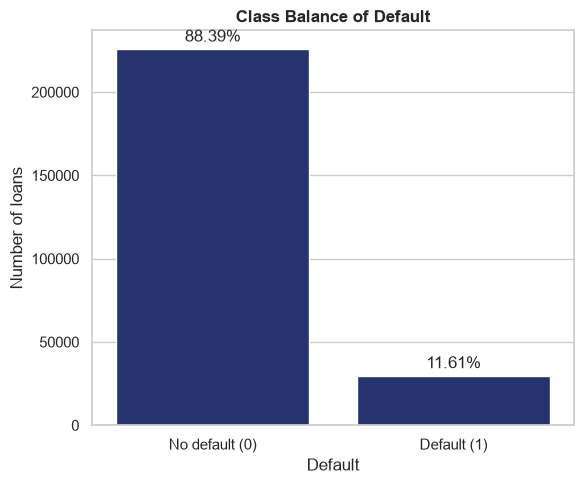

In [16]:
# Corrine: Show loan default counts and percentages.

counts = df_clean["Default"].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(2)

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(6, 5))

sns.countplot(x="Default", data=df_clean, order=[0, 1],
              ax=ax, color="#1a2b7d")

ax.set_xticks([0, 1])
ax.set_xticklabels(["No default (0)", "Default (1)"])
ax.set_ylabel("Number of loans")
ax.set_title("Class Balance of Default", fontweight="bold")

ax.bar_label(
    ax.containers[0],
    labels=[f"{pct.loc[i]:.2f}%" for i in [0, 1]],
    padding=3
)

plt.tight_layout()
plt.show()


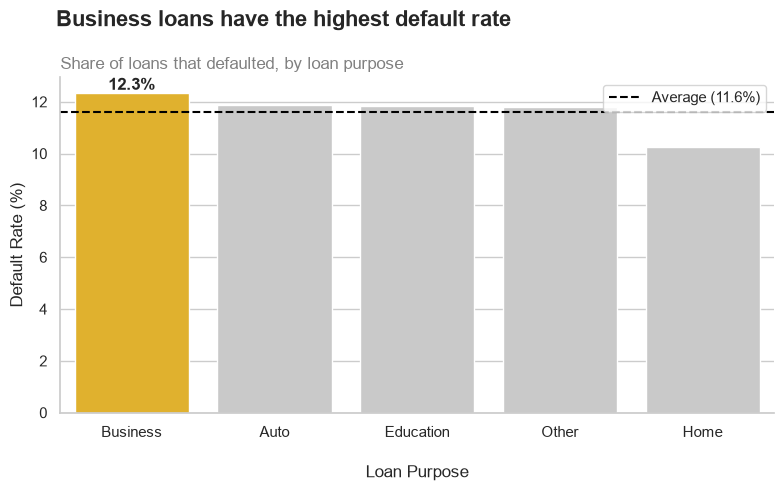

In [17]:
# Corrine: Compare default rates by loan purpose with the overall average.

loan_purpose_rates = (
    df_clean.groupby("LoanPurpose")["Default"].mean() * 100
).sort_values(ascending=False)

# Calculate the overall default rate
default_rate_all = df_clean["Default"].mean() * 100

colors = ["#fdbf11", "#c9c9c9", "#c9c9c9", "#c9c9c9", "#c9c9c9"]

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    x=loan_purpose_rates.index,
    y=loan_purpose_rates.values,
    hue=loan_purpose_rates.index,
    palette=colors,
    legend=False,
    ax=ax
)

ax.bar_label(ax.containers[0], fmt="%.1f%%", fontweight="bold")

ax.axhline(
    default_rate_all,
    color="black",
    linestyle="--",
    label=f"Average ({default_rate_all:.1f}%)"
)
ax.legend()

plt.suptitle(
    "Business loans have the highest default rate",
    x=0.08, ha="left", fontsize=16, fontweight="bold"
)

ax.set_title(
    "Share of loans that defaulted, by loan purpose",
    loc="left", fontsize=12, color="gray"
)

ax.set_xlabel("\nLoan Purpose")
ax.set_ylabel("Default Rate (%)")

sns.despine()
plt.tight_layout()
plt.show()

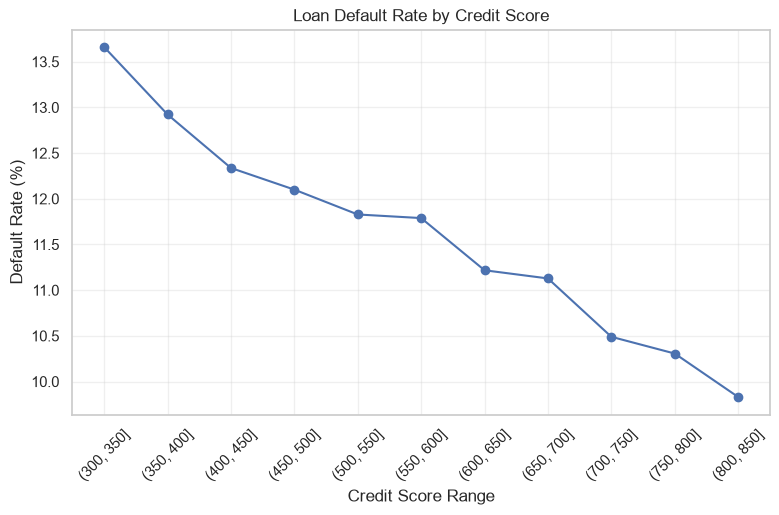

In [18]:
# Group credit scores into ranges of 50 points
df_clean["CreditScoreGroup"] = pd.cut(
    df_clean["CreditScore"],
    bins=range(300, 901, 50)
)

# Calculate the default rate for each credit score group
credit_default = df_clean.groupby(
    "CreditScoreGroup", observed=True
)["Default"].mean() * 100

# Create a line chart
plt.figure(figsize=(9, 5))
plt.plot(credit_default.index.astype(str), credit_default.values, marker="o")

# Add labels
plt.title("Loan Default Rate by Credit Score")
plt.xlabel("Credit Score Range")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()


The graph shows that borrowers with lower credit scores have higher default rates. As credit scores increase, the default rate decreases from about 13.7% to 9.8%. This suggests that credit score may help us predict loan defaults.

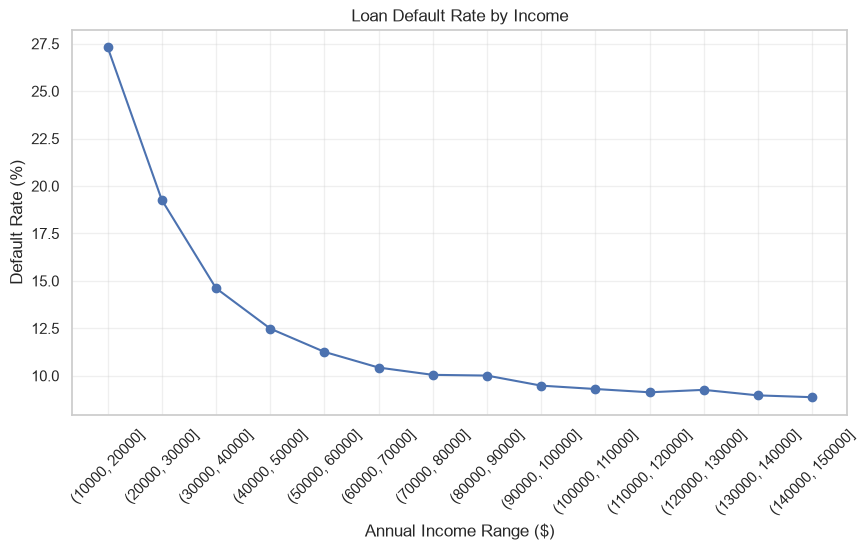

In [19]:
# Divide income into ranges of $10,000
df_clean["IncomeGroup"] = pd.cut(
    df_clean["Income"],
    bins=range(10000, 160001, 10000)
)

# Calculate the default rate for each income group
income_default = df_clean.groupby(
    "IncomeGroup", observed=True
)["Default"].mean() * 100

# Create a line chart
plt.figure(figsize=(10, 5))
plt.plot(income_default.index.astype(str),
         income_default.values, marker="o")

# Add labels
plt.title("Loan Default Rate by Income")
plt.xlabel("Annual Income Range ($)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()


The graph shows that borrowers with lower incomes have higher default rates. As income increases, the default rate decreases, especially for lower-income borrowers. This suggests that income may be an important factor in predicting loan defaults.

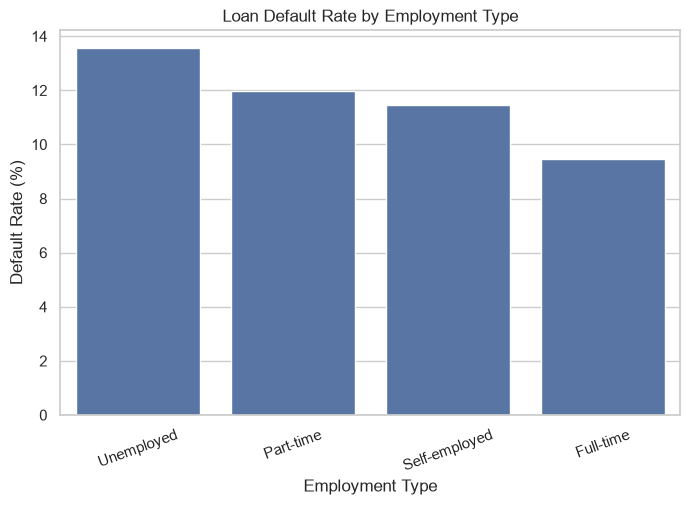

In [20]:
# Calculate the default rate for each employment type
employment_default = (
    df_clean.groupby("EmploymentType")["Default"].mean() * 100
)

# Sort from highest to lowest default rate
employment_default = employment_default.sort_values(ascending=False)

# Create a bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x=employment_default.index, y=employment_default.values)

# Add labels
plt.title("Loan Default Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)

plt.show()


Unemployed borrowers have the highest default rate, while full-time employees have the lowest.

This suggests that employment type may be related to loan default risk.

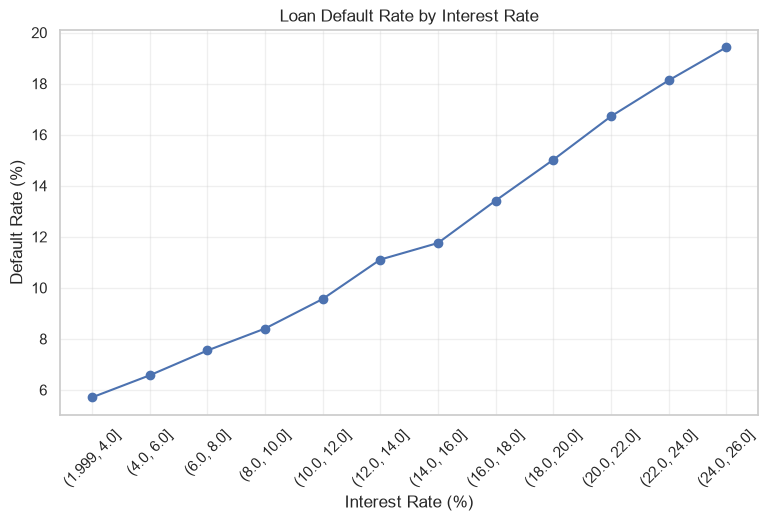

In [21]:
# Divide interest rates into groups of 2 percentage points
df_clean["InterestRateGroup"] = pd.cut(
    df_clean["InterestRate"],
    bins=range(2, 28, 2),
    include_lowest=True
)

# Calculate the default rate for each interest rate group
interest_default = df_clean.groupby(
    "InterestRateGroup", observed=True
)["Default"].mean() * 100

# Create a line chart
plt.figure(figsize=(9, 5))
plt.plot(interest_default.index.astype(str),
         interest_default.values, marker="o")

# Add labels
plt.title("Loan Default Rate by Interest Rate")
plt.xlabel("Interest Rate (%)")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.show()


The graph shows that borrowers with higher interest rates have higher default rates. The default rate increases from about 5.8% to 19.4% as interest rates increase. This suggests that interest rate may be an important factor in predicting loan defaults.

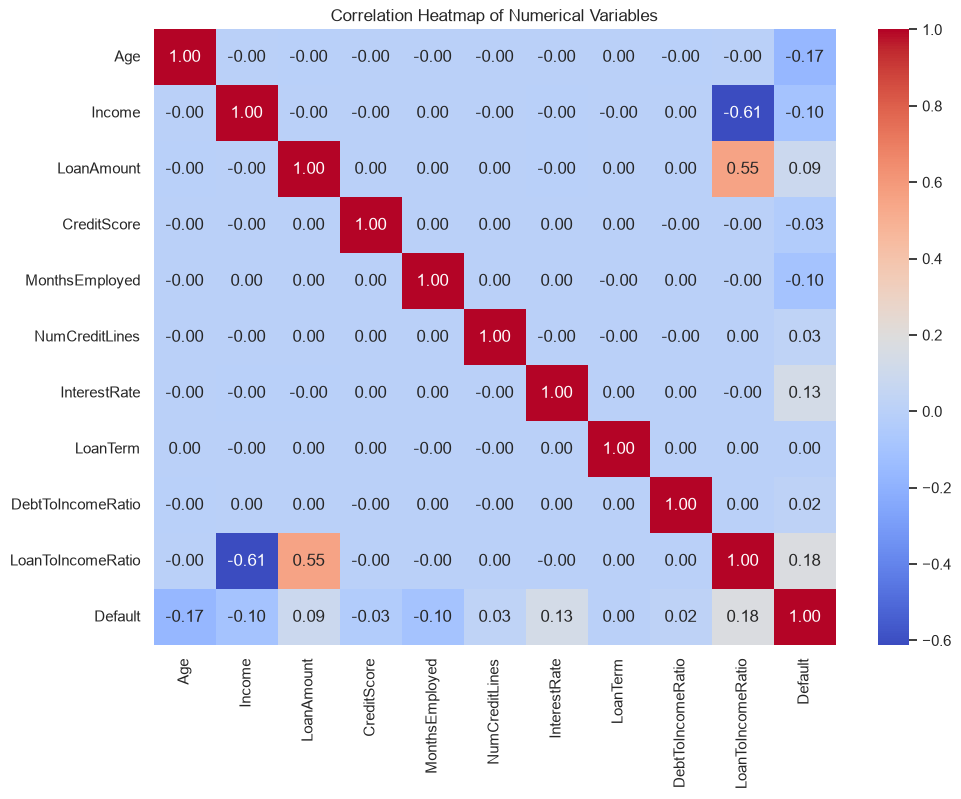

In [22]:
# Select the original numerical variables and our new feature
numeric_cols = [
    "Age", "Income", "LoanAmount", "CreditScore",
    "MonthsEmployed", "NumCreditLines", "InterestRate",
    "LoanTerm", "DebtToIncomeRatio", "LoanToIncomeRatio",
    "Default"
]

# Calculate correlations
corr = df_clean[numeric_cols].corr()

# Create a heatmap
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

# Add a title
plt.title("Correlation Heatmap of Numerical Variables")

plt.show()


The heatmap shows that loan-to-income ratio, age, and interest rate have the strongest relationships with loan default among the numerical variables. People with larger loans compared to their income, younger borrowers, and those with higher interest rates tend to have higher default rates. but these relationships are not very strong.

## Deeper EDA: When do borrowers have higher default rates?[¶](#Deeper-EDA:-When-do-borrowers-have-higher-default-rates?)

**Question:** Do age and interest rate together show differences in loan default rates?

We already looked at these variables separately. Here we compare them together to find groups with higher or lower default rates. The values show the percentage of borrowers who defaulted in each group, not proof that either factor causes default.

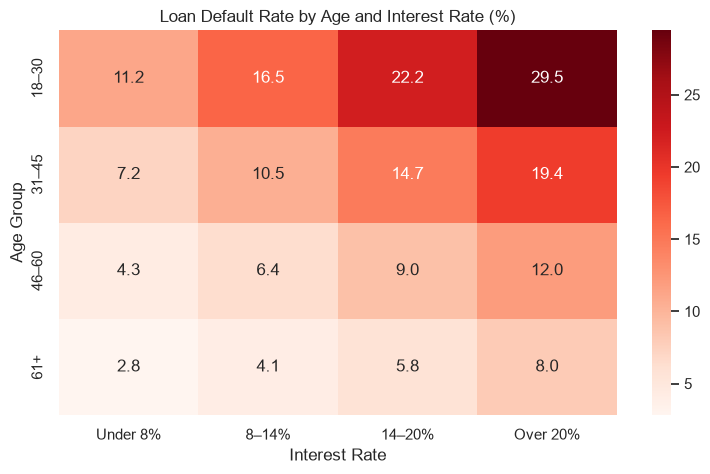

In [23]:
# Make age and interest rate groups for this chart only
eda_risk = df_clean.copy()
eda_risk["AgeGroup"] = pd.cut(
    eda_risk["Age"], bins=[17, 30, 45, 60, 100],
    labels=["18–30", "31–45", "46–60", "61+"]
)
eda_risk["RateGroup"] = pd.cut(
    eda_risk["InterestRate"], bins=[0, 8, 14, 20, 100],
    labels=["Under 8%", "8–14%", "14–20%", "Over 20%"]
)

# Calculate the default rate for each combination
risk_table = eda_risk.pivot_table(
    index="AgeGroup", columns="RateGroup", values="Default",
    aggfunc="mean", observed=True
) * 100

# Plot the default rates
plt.figure(figsize=(9, 5))
sns.heatmap(risk_table, annot=True, fmt=".1f", cmap="Reds")
plt.title("Loan Default Rate by Age and Interest Rate (%)")
plt.xlabel("Interest Rate")
plt.ylabel("Age Group")
plt.show()


### Interpretation: Loan Default Rate by Age and Interest Rate[¶](#Interpretation:-Loan-Default-Rate-by-Age-and-Interest-Rate)

The heatmap shows that younger borrowers with higher interest rates are more likely to default on their loans. Borrowers aged 18–30 with interest rates over 20% have the highest default rate of 29.5%. In comparison, borrowers aged 61 and older with interest rates under 8% have the lowest default rate of 2.8%. We can also see that default rates increase as interest rates increase, but decrease as borrowers get older. This shows that both age and interest rate are related to loan default risk.

## EDA Summary and Key Findings

The EDA shows that lower credit scores, lower incomes, and higher interest rates are associated with higher loan default rates. Employment type and loan purpose also influence default patterns. These findings help identify potential predictors for the classification models, although the relationships do not imply causation.

# Linear Regression

# Processing Variables 

In [24]:
#Numerical 
y=df_clean['CreditScore']
num= ['Age',
            'Income',
            'MonthsEmployed',
            'NumCreditLines',
            'InterestRate',
            'LoanTerm',
            'DebtToIncomeRatio',
            'LoanToIncomeRatio']
cateogorical = ['Education',
                'EmploymentType',
                'MaritalStatus',
                'HasMortgage',
                'HasDependents',
                'LoanPurpose',
                'HasCoSigner',
                'Default']
X = df_clean[num + cateogorical]


In [26]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            num
        ),
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            cateogorical
        )
    ],
    verbose_feature_names_out=False
)
## just remove for now   X_transformed = preprocessor.fit_transform(X)

# Do Train Test Split 

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=6021
)

# Create Models and Fit

1. Linear Model 
2. Polynomial Model Degree 2 
3. Linear Model with Lasso Regularization 
4. Polynomial Model Degree 2 with Lasso Regularization

**Did Cross Validation for Lasso to finf optimal alpha value --> used this alpha value for model 3 and 4 

Finally did cross validation for the four models AND usd test data for all four models 

In [28]:
lin_model = Pipeline([
    ("preprocessing", preprocessor),
    ("linreg", LinearRegression())
])

lin_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('linreg', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Income','MonthsEmployed',...,'LoanPurpose','HasCoSigner','Default']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix 

In [29]:
poly2_model = Pipeline([
    ("preprocessing", preprocessor),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("linreg", LinearRegression())
])

poly2_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Income','MonthsEmployed',...,'LoanPurpose','HasCoSigner','Default']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not pref

In [31]:
# done with claude help
poly2_lasso_cv_model = Pipeline([
    ("preprocessing", preprocessor),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LassoCV(cv=5,random_state=6021))
])

poly2_lasso_cv_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Income','MonthsEmployed',...,'LoanPurpose','HasCoSigner','Default']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not pref

In [32]:
# done with claude help

lasso = poly2_lasso_cv_model.named_steps["model"]
print("Best alpha:", lasso.alpha_)
print("Coefficients:", lasso.coef_)
print("Test R²:", poly2_lasso_cv_model.score(X_test, y_test))

Best alpha: 0.4415729905085446
Coefficients: [-4.18792724e-02 -6.64165315e-02 -1.57331990e-01  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  4.60723346e-01
  0.00000000e+00 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00
  0.00000000e+00  0.00000000e+00 -0.00000000e+00 -0.00000000e+00
  0.00000000e+00 -1.38702377e-01 -0.00000000e+00 -0.00000000e+00
  0.00000000e+00  0.00000000e+00 -0.00000000e+00 -1.33828026e+01
 -0.00000000e+00  0.00000000e+00 -0.00000000e+00 -4.09380580e-02
 -6.90165053e-02  0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00 -1.25467637e-02
 -0.00000000e+00 -0.00000000e+00  0.00000000e+00 -0.00000000e+00
  0.00000000e+00 -0.00000000e+00 -0.00000000e+00  0.00000000e+00
  0.00000000e+00  2.91739642e-01 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00  0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00 -0.00000000e+00 -0.00000000e

In [33]:
lin_lasso_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", Lasso(alpha=0.442))
])

lin_lasso_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Income','MonthsEmployed',...,'LoanPurpose','HasCoSigner','Default']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix a

In [34]:
poly2_lasso_model = Pipeline([
    ("preprocessing", preprocessor),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", Lasso(alpha=0.442))
])

poly2_lasso_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['Age','Income','MonthsEmployed',...,'LoanPurpose','HasCoSigner','Default']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not pref

In [35]:
# Cross Validation 
models = {
    "Linear": lin_model,
    "Poly 2": poly2_model,
    "linear reg": lin_lasso_model,
    "poly2 reg": poly2_lasso_model
}

cv = KFold(n_splits=5, shuffle=True, random_state=123)

rows = []

for name, model in models.items():
    cv_rmse = -cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error"
    )

    rows.append({
        "Model": name,
        "Mean CV RMSE": cv_rmse.mean(),
        "SD CV RMSE": cv_rmse.std(ddof=1)
    })

cv_results = pd.DataFrame(rows).sort_values("Mean CV RMSE")
display(cv_results.round(2))

,Model,Mean CV RMSE,SD CV RMSE
0,Linear,158.83,0.10
2,linear reg,158.83,0.11
3,poly2 reg,158.84,0.12
1,Poly 2,158.98,0.12


In [36]:
# Using test set
models = {
    "Linear": lin_model,
    "Poly 2": poly2_model,
    "linear reg": lin_lasso_model,
    "poly2 reg": poly2_lasso_model
}

rows = []

for name, model in models.items():
    y_hat = model.predict(X_test)

    test_mae = mean_absolute_error(y_test, y_hat)  # Added MAE
    test_rmse = np.sqrt(mean_squared_error(y_test, y_hat))
    test_r2 = r2_score(y_test, y_hat)

    rows.append({
        "Model": name,
        "Test MAE": test_mae,  # Added MAE
        "Test RMSE": test_rmse,
        "Test R²": test_r2
    })

results = pd.DataFrame(rows)
results.round(2)

,Model,Test MAE,Test RMSE,Test R²
0,Linear,137.57,158.78,0.0
1,Poly 2,137.63,158.90,-0.0
2,linear reg,137.59,158.78,0.0
3,poly2 reg,137.59,158.78,0.0


# Residual plot 

In [37]:
df_clean["predicted_poly"] = poly2_model.predict(X)
df_clean["residual_poly"] = (
    df_clean["CreditScore"] - df_clean["predicted_poly"]
)

fig = px.scatter(
    df_clean,
    x="predicted_poly",
    y="residual_poly",
    title="Residual Plot: Polynomial Degree 2 Model",
    labels={
        "predicted_poly": "Predicted",
        "residual_poly": "Residual"
    }
)

fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.show()

In [38]:
df_clean["predicted_linear"] = lin_model.predict(X)
df_clean["residual_linear"] = (
    df_clean["CreditScore"] - df_clean["predicted_linear"]
)

fig = px.scatter(
    df_clean,
    x="predicted_linear",
    y="residual_linear",
    title="Residual Plot: Linear Model",
    labels={
        "predicted_linear": "Predicted",
        "residual_linear": "Residual"
    }
)

fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.show()

In [39]:
df_clean["predicted_linear_lasso"] = lin_lasso_model.predict(X)
df_clean["residual_linear_lasso"] = (
    df_clean["CreditScore"] - df_clean["predicted_linear_lasso"]
)

fig = px.scatter(
    df_clean,
    x="predicted_linear_lasso",
    y="residual_linear_lasso",
    title="Residual Plot: Linear Model with Lasso",
    labels={
        "predicted_linear": "Predicted",
        "residual_linear": "Residual"
    }
)

fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.show()

In [40]:
df_clean["predicted_poly2_lasso"] = poly2_lasso_model.predict(X)
df_clean["residual_poly2_lasso"] = (
    df_clean["CreditScore"] - df_clean["predicted_poly2_lasso"]
)

fig = px.scatter(
    df_clean,
    x="predicted_poly2_lasso",
    y="residual_poly2_lasso",
    title="Residual Plot: Polynomial Degree 2 Model with Lasso",
    labels={
        "predicted_linear": "Predicted",
        "residual_linear": "Residual"
    }
)

fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.show()

# Figure out what variables Lasso dropped 

In [41]:
# used claude code 

feature_names = poly2_lasso_model[:-1].get_feature_names_out()
coefs = pd.Series(lasso.coef_, index=feature_names)

dropped = coefs[coefs == 0].index.tolist()
kept = coefs[coefs != 0].index.tolist()

print(f"Dropped {len(dropped)} of {len(coefs)} features:")
print(dropped)

Dropped 303 of 324 features:
['NumCreditLines', 'InterestRate', 'LoanTerm', 'DebtToIncomeRatio', 'Education_High School', "Education_Master's", 'Education_PhD', 'EmploymentType_Part-time', 'EmploymentType_Self-employed', 'EmploymentType_Unemployed', 'MaritalStatus_Married', 'MaritalStatus_Single', 'HasMortgage_Yes', 'LoanPurpose_Business', 'LoanPurpose_Education', 'LoanPurpose_Home', 'LoanPurpose_Other', 'HasCoSigner_Yes', 'Age^2', 'Age Income', 'Age MonthsEmployed', 'Age LoanTerm', 'Age DebtToIncomeRatio', 'Age LoanToIncomeRatio', 'Age Education_High School', "Age Education_Master's", 'Age Education_PhD', 'Age EmploymentType_Part-time', 'Age EmploymentType_Self-employed', 'Age EmploymentType_Unemployed', 'Age MaritalStatus_Married', 'Age HasMortgage_Yes', 'Age HasDependents_Yes', 'Age LoanPurpose_Business', 'Age LoanPurpose_Education', 'Age LoanPurpose_Home', 'Age LoanPurpose_Other', 'Age HasCoSigner_Yes', 'Age Default_1', 'Income^2', 'Income NumCreditLines', 'Income InterestRate', 'I

In [42]:
# used claude code 
# names coming out of the preprocessor (before polynomial expansion)
base_features = poly2_lasso_model.named_steps["preprocessing"].get_feature_names_out()

fully_dropped = [
    f for f in base_features
    if not any(f in term.split(" ") or term.startswith(f + "^") for term in kept)
]

print("Original predictors with no surviving terms:", fully_dropped)

Original predictors with no surviving terms: ['Education_High School', "Education_Master's", 'Education_PhD', 'EmploymentType_Part-time', 'EmploymentType_Self-employed', 'EmploymentType_Unemployed', 'MaritalStatus_Married', 'LoanPurpose_Business', 'LoanPurpose_Education', 'LoanPurpose_Home', 'LoanPurpose_Other', 'HasCoSigner_Yes']


In [43]:
df_kept = pd.DataFrame(kept)
print(df_kept)

                                   0
0                                Age
1                             Income
2                     MonthsEmployed
3                  LoanToIncomeRatio
4                  HasDependents_Yes
5                          Default_1
6                 Age NumCreditLines
7                   Age InterestRate
8           Age MaritalStatus_Single
9              Income MonthsEmployed
10            Income HasMortgage_Yes
11       MonthsEmployed InterestRate
12           MonthsEmployed LoanTerm
13  MonthsEmployed LoanToIncomeRatio
14  NumCreditLines DebtToIncomeRatio
15    InterestRate DebtToIncomeRatio
16    InterestRate LoanToIncomeRatio
17      InterestRate HasMortgage_Yes
18                        LoanTerm^2
19               HasDependents_Yes^2
20                       Default_1^2


# Figure out variables with right skew 

In [44]:

fig = px.scatter(
    df_clean,
    x="Income",
    y="CreditScore",
    opacity=0.65,
    title="Income Versus CreditScore",
)
fig.update_traces(marker=dict(size=2, opacity =0.2)) # claude code 
fig.show()

There appears to be little or no relationship between income and credit score in this dataset. Higher-income borrowers do not consistently have higher credit scores.

### Conclusion: Regression Models

Our main research question is which factors help predict whether a borrower will default on a loan? Since credit scores are related to creditworthiness and financial risk, we first explored whether borrowers' financial and personal information could predict their credit scores.

We compared four regression models, and all performed similarly, with an MAE around 137.6, RMSE around 158.8, and R² close to 0. This means the models could not explain much of the variation in credit scores. Adding polynomial features and Lasso did not improve performance. These results suggest that the available features are not strong predictors of credit scores. Therefore, we will focus on classification models to directly predict loan defaults, which is our main goal.

Logistic Regression: Predicting Loan Default

Our goal is to predict whether a borrower will repay their loan or default. Default (1) means failing to repay the loan as required, while No Default (0) means making payments as agreed. We use logistic regression to predict the chance of default based on the borrower's financial and personal information.

Building the Logisitc Regression

In [45]:
# save the target column in y
y = df_clean['Default']

# save the predictors or features in x
x = df_clean[['Age', 'Income', 'LoanAmount', 'CreditScore',
              'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
              'DebtToIncomeRatio', 'Education', 'EmploymentType', 'MaritalStatus',
              'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
              'LoanToIncomeRatio']]

# save the categorical variables for preprocessing
cats = ['Education', 'EmploymentType', 'MaritalStatus',
        'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']

# save the numerical variables for preprocessing
nums = ['Age', 'Income', 'LoanAmount', 'CreditScore',
        'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
        'DebtToIncomeRatio', 'LoanToIncomeRatio']

Splitting into train, test, and validation. Will use validation set to find the threshold

In [46]:
# split data into training and test
x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=0.2, random_state=6021, stratify=y
)

# split data into training and test
x_train, x_val, y_train, y_val = train_test_split(
    x_train_val, y_train_val, test_size=0.25, random_state=6021, stratify=y_train_val
)

display(pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Rows': [len(y_train), len(y_val), len(y_test)],
    'Default rate' : [y_train.mean(), y_val.mean(), y_test.mean()]
}))

,Split,Rows,Default rate
0,Train,153207,0.116124
1,Validation,51070,0.116135
2,Test,51070,0.116135


In [47]:
# create the order of the pipeline
preprocess = ColumnTransformer(transformers=[
    ("encoder", OneHotEncoder(drop='first', handle_unknown='ignore'), cats),
    ("numeric", StandardScaler(), nums)
])

In [48]:
# create a log reg model
logreg=LogisticRegression(max_iter=5000, random_state=123)

# create a preporcessing pipeline
pipe = Pipeline(steps=[("preprocess", preprocess), ("model", logreg)])

# fit
pipe.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Age','Income','LoanAmount',...,'LoanPurpose','HasCoSigner', 'LoanToIncomeRatio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('encoder', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [49]:
# get the predicted probability of default (1)
p_train = pipe.predict_proba(x_train)[:, 1]
p_val = pipe.predict_proba(x_val)[:, 1]
p_test = pipe.predict_proba(x_test)[:, 1]

# get the log odds
log_odds_train = pipe.decision_function(x_train)
log_odds_val = pipe.decision_function(x_val)
log_odds_test = pipe.decision_function(x_test)

In [50]:
# get feature names and model coefficients
feature_names = pipe.named_steps['preprocess'].get_feature_names_out()
beta = pipe.named_steps['model'].coef_[0]

# calculate odds ratios
coefs = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': beta,
    'Odds Ratio': np.exp(beta)
})

print('Intercept:', pipe.named_steps['model'].intercept_[0])

# sort features by coefficient
coefs.sort_values('Coefficient', ascending=False)

Intercept: -2.091008632947793


,Feature,Coefficient,Odds Ratio
21,numeric__InterestRate,0.461079,1.585784
24,numeric__LoanToIncomeRatio,0.460122,1.584267
5,encoder__EmploymentType_Unemployed,0.440038,1.552767
3,encoder__EmploymentType_Part-time,0.282399,1.326308
4,encoder__EmploymentType_Self-employed,0.242719,1.274710
20,numeric__NumCreditLines,0.104132,1.109747
0,encoder__Education_High School,0.080002,1.083289
23,numeric__DebtToIncomeRatio,0.054313,1.055815
10,encoder__LoanPurpose_Business,0.042884,1.043817
16,numeric__Income,0.012276,1.012352


In [51]:
# defining a function that will get the pred, the TN, ..., and return all the metrics 
def metrics_at(y_true, probabilities, threshold):
    pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    return {'Threshold': threshold, 'TP':tp, 'FP':fp, 'FN':fn, 'TN':tn,
            'Accuracy':accuracy_score(y_true,pred),
            'Precision':precision_score(y_true,pred,zero_division=0),
            'Recall':recall_score(y_true,pred,zero_division=0),
            'F1':f1_score(y_true,pred,zero_division=0),
            'ROC AUC':roc_auc_score(y_true,probabilities),
            'Log loss':log_loss(y_true,probabilities)}

# metrics at threshold = 0.5 for the training data and the validation data
baseline = pd.DataFrame([
    {'Split':'Train', **metrics_at(y_train,p_train,0.50)},
    {'Split':'Validation', **metrics_at(y_val,p_val,0.50)}])
display(baseline.round(4))

,Split,Threshold,TP,FP,FN,TN,Accuracy,Precision,Recall,F1,ROC AUC,Log loss
0,Train,0.5,1187,766,16604,134650,0.8866,0.6078,0.0667,0.1202,0.7557,0.3120
1,Validation,0.5,390,226,5541,44913,0.8871,0.6331,0.0658,0.1191,0.7608,0.3098


At the default threshold of 0.50, logistic regression achieves about 88.7% accuracy on both training and validation data. However, validation recall is only 6.58%, meaning the model misses most actual defaults. This suggests that accuracy alone is not enough to evaluate our model, so we will explore different classification thresholds to improve recall.

In [53]:
# testing a range of different thresholds on the validation data 
thresholds = np.round(np.arange(0.05,0.951,0.01),2)
validation_results = pd.DataFrame([
    metrics_at(y_val,p_val,t) for t in thresholds
])
# show the metrics for the thresholds that satisfy the threholds in this list 
display(validation_results.loc[validation_results['Threshold'].isin([0.10,0.15,0.20,0.25,0.30,0.50,0.70,0.90])].round(3))
# plot the mertics 
fig = go.Figure()
for col,label in [('FP','False positives (false alarms)'),('FN','False negatives (missed defaults)')]:
    fig.add_trace(go.Scatter(x=validation_results['Threshold'],
                             y=validation_results[col],mode='lines',name=label))
fig.update_layout(title='Validation errors vs classification threshold',
                  xaxis_title='Threshold',yaxis_title='Number of borrowers')
fig.show()

,Threshold,TP,FP,FN,TN,Accuracy,Precision,Recall,F1,ROC AUC,Log loss
5,0.10,4434,16771,1497,28368,0.642,0.209,0.748,0.327,0.761,0.31
10,0.15,3441,9506,2490,35633,0.765,0.266,0.580,0.365,0.761,0.31
15,0.20,2594,5446,3337,39693,0.828,0.323,0.437,0.371,0.761,0.31
20,0.25,1897,3202,4034,41937,0.858,0.372,0.320,0.344,0.761,0.31
25,0.30,1381,1869,4550,43270,0.874,0.425,0.233,0.301,0.761,0.31
45,0.50,390,226,5541,44913,0.887,0.633,0.066,0.119,0.761,0.31
65,0.70,76,23,5855,45116,0.885,0.768,0.013,0.025,0.761,0.31
85,0.90,1,0,5930,45139,0.884,1.000,0.000,0.000,0.761,0.31


Lowering the classification threshold increases recall but also increases false positives. At 0.50, the model detects only 6.6% of defaults. At 0.20, recall improves to 43.7%, with 82.8% accuracy and an F1 score of 0.371. This shows that a lower threshold can help identify more borrowers at risk of default.

In [54]:
MIN_RECALL = 0.70  # arbitrary choice, saying we want a min recall of .7 based off of outside cost, ex. FN are expensive
eligible = validation_results[validation_results['Recall'] >= MIN_RECALL]
if eligible.empty:
    print('No threshold meets the recall target; choosing highest validation F1 instead.')
    eligible = validation_results
chosen = eligible.sort_values(['F1','Precision'],ascending=False).iloc[0]
selected_threshold = float(chosen['Threshold'])
print('Selected threshold:',selected_threshold)
display(chosen.to_frame('Validation result').T.round(4))

Selected threshold: 0.11


,Threshold,TP,FP,FN,TN,Accuracy,Precision,Recall,F1,ROC AUC,Log loss
Validation result,0.11,4236.0,14909.0,1695.0,30230.0,0.6749,0.2213,0.7142,0.3379,0.7608,0.3098


Threshold of 0.11 meets 0.70 min recall, minimizes out false negatives

In [55]:
# compare the default and validation-selected thresholds on the test set
final_metrics = pd.DataFrame([
    {'Rule': 'Default 0.50', **metrics_at(y_test, p_test, 0.50)},
    {'Rule': 'Validation-selected', **metrics_at(y_test, p_test, selected_threshold)}
])

display(final_metrics.round(4))

# plot confusion matrices for both thresholds
for rule, t in [('Default 0.50', 0.50), ('Validation-selected', selected_threshold)]:
    pred = (p_test >= t).astype(int)

    cm = confusion_matrix(y_test, pred, labels=[1, 0])

    cm_df = pd.DataFrame(
        cm,
        index=['Actual default', 'Actual no default'],
        columns=['Predicted default', 'Predicted no default']
    )

    fig = px.imshow(
        cm_df,
        text_auto=True,
        color_continuous_scale='Blues',
        title=f'Test Confusion Matrix — {rule} (t={t:.2f})'
    )

    fig.show()

,Rule,Threshold,TP,FP,FN,TN,Accuracy,Precision,Recall,F1,ROC AUC,Log loss
0,Default 0.50,0.50,404,258,5527,44881,0.8867,0.6103,0.0681,0.1226,0.7582,0.3107
1,Validation-selected,0.11,4187,14934,1744,30205,0.6734,0.2190,0.7060,0.3343,0.7582,0.3107


In [56]:
fpr,tpr,_=roc_curve(y_test,p_test)
fig=go.Figure()
fig.add_trace(go.Scatter(x=fpr,y=tpr,mode='lines',name=f'Logit (AUC={roc_auc_score(y_test,p_test):.3f})'))
fig.add_trace(go.Scatter(x=[0,1],y=[0,1],mode='lines',line=dict(dash='dash'),name='Random baseline'))
fig.update_layout(title='Test ROC curve',xaxis_title='False positive rate',yaxis_title='True positive rate')
fig.show()

prob_true,prob_pred=calibration_curve(y_test,p_test,n_bins=10,strategy='quantile')
fig=go.Figure()
fig.add_trace(go.Scatter(x=prob_pred,y=prob_true,mode='lines+markers',name='Logistic regression'))
fig.add_trace(go.Scatter(x=[0,1],y=[0,1],mode='lines',line=dict(dash='dash'),name='Perfect calibration'))
fig.update_layout(title='Test calibration',xaxis_title='Mean predicted default probability',
                  yaxis_title='Observed default frequency')
fig.show()

We used logistic regression to predict loan defaults. At the default threshold of 0.50, the model achieved 88.7% accuracy but had only 6.6% recall on the validation set, meaning it missed most actual defaults.

Lowering the threshold to 0.11 increased recall to 71.4%, but precision decreased to 22.1%, leading to more false positives. In banking, missing actual defaults can lead to financial losses, while false positives can mean losing good customers and revenue. Therefore, banks need to balance precision and recall when choosing a threshold.

### K-Nearest Neighbors (KNN)

**Goal:** Predict whether a new loan will default.

**How KNN works:**
1. Measures how similar a new loan is to loans in the training data.
2. Finds the K closest loans (neighbors).
3. Uses the neighbors' outcomes to predict whether the new loan will default.

**Steps for building the model:**
1. Split the data into training and test sets, keeping the test set for final evaluation.
2. Use cross-validation to test different values of K and distance measures (Euclidean and Manhattan).
3. Select the model with the best cross-validation performance.
4. Train the selected model using all training data.
5. Evaluate its final performance on the test set.

In [57]:
X_train_knn, X_test_knn, y_train_knn, y_test_knn = train_test_split(
    df_clean[cats + nums], df_clean['Default'],
    test_size=0.25, random_state=6021, stratify=df_clean['Default']
) # stratify because we have class imbalance

display(pd.DataFrame({
    'Split': ['Train (used for CV)', 'Test'],
    'Rows': [len(y_train_knn), len(y_test_knn)],
    'Default rate': [y_train_knn.mean(), y_test_knn.mean()]
}))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # for 5-fold cross-validation

,Split,Rows,Default rate
0,Train (used for CV),191510,0.116130
1,Test,63837,0.116124


# Preprocessing and pipeline

In [58]:
# create the order of the pipeline
preprocess_knn = ColumnTransformer(transformers=[
    ("encoder", OneHotEncoder(drop='if_binary', handle_unknown='ignore'), cats),
    # got rid of drop='first', since KNN does not have multicollinearity issues (no coefficients)
    # drop='if_binary' keeps binary features from counting double in the distance.
    ("numeric", StandardScaler(), nums) # distance is scale-sensitive, so v important to standardize predictors
])

pipe_knn = Pipeline([
    ("preprocess", preprocess_knn),
    ("knn", KNeighborsClassifier())
])

# Tuning: choosing K and distance metric

In [59]:
param_grid = {
    "knn__n_neighbors": range(1, 41, 2),
     # number of neighbors: outcome is binary, we use odd numbers to avoid ties
    "knn__metric": ["euclidean", "manhattan"], # "similarity" measure
    "knn__weights": ["uniform", "distance"] # voting rule
}

grid_knn = GridSearchCV(
    pipe_knn, param_grid, cv=cv, scoring="balanced_accuracy",
    return_train_score=True,
    n_jobs=-1, # use all available CPU cores (so fits run in parallel AKA faster)
    error_score="raise" # if any fit fails, stop and show error
) 
grid_knn.fit(X_train_knn, y_train_knn)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__metric': ['euclidean', 'manhattan'], 'knn__n_neighbors': range(1, 41, 2), 'knn__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_i

In [60]:
results_df = pd.DataFrame(grid_knn.cv_results_)
results_df["k"] = results_df["param_knn__n_neighbors"].astype(int)
results_df["metric"] = results_df["param_knn__metric"]
results_df["cv_balanced_error"] = 1 - results_df["mean_test_score"]
results_df["train_balanced_error"] = 1 - results_df["mean_train_score"]
results_df["weights"] = results_df["param_knn__weights"]

best_k = grid_knn.best_params_["knn__n_neighbors"]
best_metric = grid_knn.best_params_["knn__metric"]
best_error = 1 - grid_knn.best_score_
best_weights = grid_knn.best_params_["knn__weights"]

print("Best K:", best_k)
print("Best distance:", best_metric)
print("Best voting rule (weights):", best_weights)
print(f"Best CV balanced classification error: {best_error:.3f}")

Best K: 1
Best distance: euclidean
Best voting rule (weights): uniform
Best CV balanced classification error: 0.455


In [61]:
# create text label for each metric/voting combo so each line can be plotted separately
results_df["configuration"] = results_df["metric"] + " + " + results_df["weights"] 

fig = px.line(
    results_df.sort_values("k"), x="k", y="cv_balanced_error", color="configuration", markers=True,
    labels={"k": "Number of neighbors (K)",
            "cv_balanced_error": "CV balanced classification error",
            "configuration": "Metric / voting"},
    title=f"Choosing K: {best_metric}, {best_weights} votes, K = {best_k}"
)
fig.add_scatter(
    x=[best_k], y=[best_error], mode="markers+text",
    text=[f"Best K = {best_k}"], textposition="top center", name="Selected model"
)
fig.update_layout(hovermode="x unified")
fig.show()

- CV balanced error was lowest at K=1 using Euclidean distance (0.455). It looks like Euclidean beats Manhattan at every K. This is CV balanced error is only slightly better than chance (0.5) with about 11% defaults; larger K lets non defaulters dominate the vote, so balanced error rises toward 0.5 as K grows.

In [62]:
curve = results_df.loc[
(results_df["metric"] == "euclidean") &
(results_df["weights"] == "uniform"),
["k", "train_balanced_error", "cv_balanced_error"]
].sort_values("k")
display(curve.round(4))
curve_plot = curve.rename(columns={
"train_balanced_error": "Training folds",
"cv_balanced_error": "Held-out CV folds"
})
fig = px.line(
curve_plot, x="k", y=["Training folds", "Held-out CV folds"],
markers=True, labels={"k": "Number of neighbors (K)",
"value": "Mean balanced error", "variable": "Data"},
title="Changing K: standardized Euclidean distance, uniform votes"
)
fig.show()

,k,train_balanced_error,cv_balanced_error
0,1,0.0000,0.4549
2,3,0.3407,0.4589
4,5,0.4099,0.4656
6,7,0.4382,0.4697
8,9,0.4524,0.4737
10,11,0.4609,0.4761
12,13,0.4662,0.4777
14,15,0.4702,0.4796
16,17,0.4732,0.4806
18,19,0.4753,0.4810


In [63]:
pipe2 = grid_knn.best_estimator_
y_pred = pipe2.predict(X_test_knn)

In [64]:
acc = accuracy_score(y_test_knn, y_pred)
bal_acc = balanced_accuracy_score(y_test_knn, y_pred)

print(f"Accuracy: {acc:.3f}")
print(f"Classification error (1 - accuracy): {1 - acc:.3f}")
print(f"Balanced accuracy: {bal_acc:.3f}")
print(f"Balanced classification error: {1 - bal_acc:.3f}")
print(f"Precision for Default: {precision_score(y_test_knn, y_pred, zero_division=0):.3f}")
print(f"Recall for Default: {recall_score(y_test_knn, y_pred, zero_division=0):.3f}")
print(f"F1 for Default: {f1_score(y_test_knn, y_pred, zero_division=0):.3f}")

Accuracy: 0.816
Classification error (1 - accuracy): 0.184
Balanced accuracy: 0.545
Balanced classification error: 0.455
Precision for Default: 0.199
Recall for Default: 0.192
F1 for Default: 0.196


In [65]:
cm = confusion_matrix(y_test_knn, y_pred, labels=[0, 1])

fig = px.imshow(
    cm, text_auto=True, color_continuous_scale="Blues",
    x=["No default", "Default"], y=["No default", "Default"],
    labels={"x": "Predicted label", "y": "Actual label", "color": "Borrowers"},
    title="Test-set confusion matrix: selected kNN"
)
fig.show()

### KNN Model Conclusion

The best KNN model used K = 1, Euclidean distance, and uniform voting, selected through 5-fold cross-validation.

The model achieved 81.6% accuracy and 54.5% balanced accuracy. However, its recall for loan defaults was only 19.2%, meaning it failed to identify most borrowers who actually defaulted.

These results suggest that KNN is not particularly effective at detecting loan defaults in our imbalanced dataset. Although overall accuracy was relatively high, recall and balanced accuracy provide a better understanding of its performance.

# K-Means Clustering

K-Means is an unsupervised learning method that groups borrowers based on similarities in their financial and demographic characteristics.

Unlike Logistic Regression and KNN, K-Means does not use loan default outcomes during clustering.

Our goal is to identify borrower groups with similar characteristics and investigate whether their loan default rates differ.